In [4]:
pip install pandas numpy seaborn matplotlib tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
plt.style.use('ggplot')
from matplotlib.pyplot import figure

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12,8) # Adjusts the configuration of the plots we will create


# Read in the data

df = pd.read_excel('Current_Generation_Movie_Analysis.xlsx')

In [4]:
df.head()


,Movie_ID,Movie_Name,Release_Year,Genre,Director,Lead_Actor,Language,Budget_Cr,Worldwide_Box_Office_Cr,IMDb_Rating,Runtime_Minutes,Story_Rating_5,Acting_Rating_5,Music_Rating_5,Audience_Rating_5,Profit_Cr,Box_Office_to_Budget_Ratio,Ratings_Average_5
0,1,Kalki 2898 AD,2024,Sci-Fi Action,Nag Ashwin,Prabhas,Telugu,600,1042,7.0,180,3.5,4.2,4.0,4.3,442,1.74,4.00
1,2,Pushpa 2: The Rule,2024,Action Drama,Sukumar,Allu Arjun,Telugu,500,1742,6.1,200,4.1,4.4,4.2,4.5,1242,3.48,4.30
2,3,Devara: Part 1,2024,Action Drama,Koratala Siva,N. T. Rama Rao Jr.,Telugu,300,521,6.0,178,3.4,3.8,3.7,3.9,221,1.74,3.70
3,4,Stree 2,2024,Horror Comedy,Amar Kaushik,Rajkummar Rao,Hindi,60,874,7.0,149,4.2,4.3,4.4,4.4,814,14.57,4.32
4,5,Bhool Bhulaiyaa 3,2024,Horror Comedy,Anees Bazmee,Kartik Aaryan,Hindi,150,423,5.2,158,3.3,3.7,3.6,3.8,273,2.82,3.60


In [5]:
print("Rows and columns:", df.shape)
print("Total movies:", len(df))


Rows and columns: (30, 18)
Total movies: 30


In [6]:
df.columns


Index(['Movie_ID', 'Movie_Name', 'Release_Year', 'Genre', 'Director',
       'Lead_Actor', 'Language', 'Budget_Cr', 'Worldwide_Box_Office_Cr',
       'IMDb_Rating', 'Runtime_Minutes', 'Story_Rating_5', 'Acting_Rating_5',
       'Music_Rating_5', 'Audience_Rating_5', 'Profit_Cr',
       'Box_Office_to_Budget_Ratio', 'Ratings_Average_5'],
      dtype='str')

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Movie_ID                    30 non-null     int64  
 1   Movie_Name                  30 non-null     str    
 2   Release_Year                30 non-null     int64  
 3   Genre                       30 non-null     str    
 4   Director                    30 non-null     str    
 5   Lead_Actor                  30 non-null     str    
 6   Language                    30 non-null     str    
 7   Budget_Cr                   30 non-null     int64  
 8   Worldwide_Box_Office_Cr     30 non-null     int64  
 9   IMDb_Rating                 30 non-null     float64
 10  Runtime_Minutes             30 non-null     int64  
 11  Story_Rating_5              30 non-null     float64
 12  Acting_Rating_5             30 non-null     float64
 13  Music_Rating_5              30 non-null     floa

In [8]:
df.describe()


,Movie_ID,Release_Year,Budget_Cr,Worldwide_Box_Office_Cr,IMDb_Rating,Runtime_Minutes,Story_Rating_5,Acting_Rating_5,Music_Rating_5,Audience_Rating_5,Profit_Cr,Box_Office_to_Budget_Ratio,Ratings_Average_5
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.00000,30.00000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,15.500000,2023.466667,183.366667,490.133333,7.073333,158.80000,4.01000,4.230000,4.150000,4.250000,306.766667,4.901000,4.159667
std,8.803408,0.776079,172.334975,436.558858,1.087843,18.15147,0.39335,0.289053,0.324569,0.244597,343.160934,5.468764,0.307633
min,1.000000,2022.000000,10.000000,70.000000,4.500000,118.00000,3.20000,3.500000,3.400000,3.700000,-30.000000,0.700000,3.450000
25%,8.250000,2023.000000,30.000000,156.250000,6.175000,147.25000,3.70000,4.000000,3.925000,4.100000,76.250000,1.740000,3.932500
50%,15.500000,2024.000000,110.000000,373.500000,7.100000,159.50000,4.05000,4.250000,4.100000,4.250000,148.000000,2.920000,4.165000
75%,22.750000,2024.000000,287.500000,616.250000,8.000000,169.00000,4.37500,4.475000,4.475000,4.400000,399.750000,4.350000,4.425000
max,30.000000,2024.000000,600.000000,1742.000000,8.800000,200.00000,4.60000,4.700000,4.700000,4.700000,1242.000000,25.000000,4.650000


In [9]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [10]:
print("Duplicate movie names:", df["Movie_Name"].duplicated().sum())


Duplicate movie names: 0


In [11]:
df.isnull().sum()


Movie_ID                      0
Movie_Name                    0
Release_Year                  0
Genre                         0
Director                      0
Lead_Actor                    0
Language                      0
Budget_Cr                     0
Worldwide_Box_Office_Cr       0
IMDb_Rating                   0
Runtime_Minutes               0
Story_Rating_5                0
Acting_Rating_5               0
Music_Rating_5                0
Audience_Rating_5             0
Profit_Cr                     0
Box_Office_to_Budget_Ratio    0
Ratings_Average_5             0
dtype: int64

In [12]:
df.loc[df["Worldwide_Box_Office_Cr"].idxmax(),
       ["Movie_Name", "Worldwide_Box_Office_Cr"]]


Movie_Name                 Pushpa 2: The Rule
Worldwide_Box_Office_Cr                  1742
Name: 1, dtype: object

In [13]:
df.loc[df["Budget_Cr"].idxmax(),
       ["Movie_Name", "Budget_Cr"]]


Movie_Name    Kalki 2898 AD
Budget_Cr               600
Name: 0, dtype: object

In [14]:
print("Average IMDb Rating:", round(df["IMDb_Rating"].mean(), 2))


Average IMDb Rating: 7.07


In [15]:
df.nlargest(5, "Worldwide_Box_Office_Cr")[
    ["Movie_Name", "Worldwide_Box_Office_Cr", "IMDb_Rating"]
]


,Movie_Name,Worldwide_Box_Office_Cr,IMDb_Rating
1,Pushpa 2: The Rule,1742,6.1
25,RRR,1230,7.8
26,KGF: Chapter 2,1200,8.2
20,Jawan,1160,6.9
28,Pathaan,1050,5.9


In [16]:
df["Profit_Cr"] = (
    df["Worldwide_Box_Office_Cr"] - df["Budget_Cr"]
)

df[["Movie_Name", "Budget_Cr",
    "Worldwide_Box_Office_Cr", "Profit_Cr"]].head()


,Movie_Name,Budget_Cr,Worldwide_Box_Office_Cr,Profit_Cr
0,Kalki 2898 AD,600,1042,442
1,Pushpa 2: The Rule,500,1742,1242
2,Devara: Part 1,300,521,221
3,Stree 2,60,874,814
4,Bhool Bhulaiyaa 3,150,423,273


In [17]:
df.nlargest(5, "Profit_Cr")[
    ["Movie_Name", "Profit_Cr"]
]


,Movie_Name,Profit_Cr
1,Pushpa 2: The Rule,1242
26,KGF: Chapter 2,1100
20,Jawan,860
3,Stree 2,814
28,Pathaan,800


In [18]:
df.groupby("Language")["Worldwide_Box_Office_Cr"].mean().sort_values(
    ascending=False
)


Language
Kannada      800.00
Telugu       791.00
Hindi        504.40
Tamil        334.25
Malayalam    160.00
Name: Worldwide_Box_Office_Cr, dtype: float64

In [19]:
import matplotlib.pyplot as plt


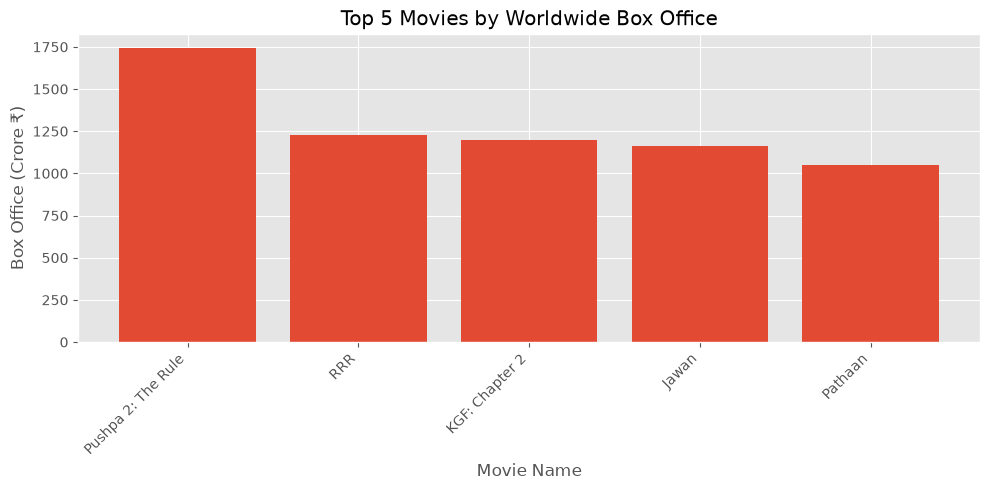

In [20]:
top5 = df.nlargest(5, "Worldwide_Box_Office_Cr")

plt.figure(figsize=(10, 5))
plt.bar(top5["Movie_Name"], top5["Worldwide_Box_Office_Cr"])

plt.title("Top 5 Movies by Worldwide Box Office")
plt.xlabel("Movie Name")
plt.ylabel("Box Office (Crore ₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


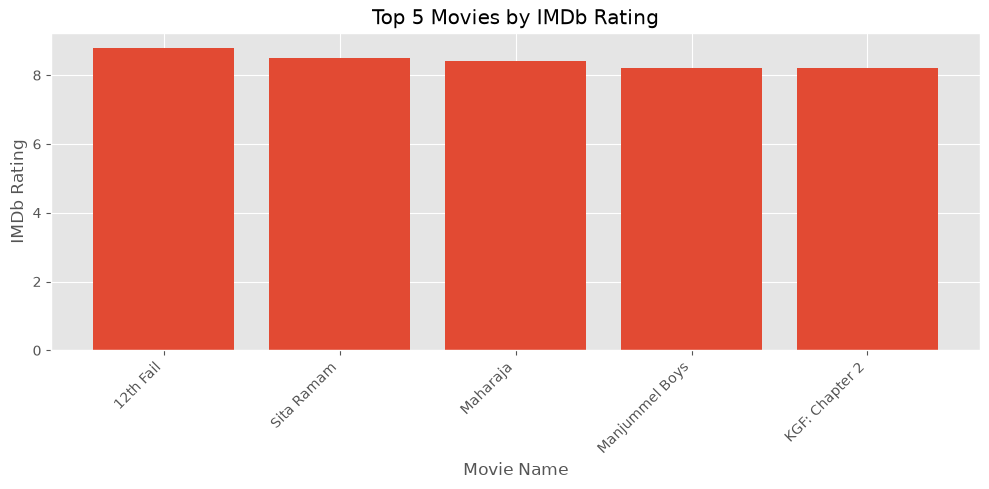

In [21]:
top_rated = df.nlargest(5, "IMDb_Rating")

plt.figure(figsize=(10, 5))
plt.bar(top_rated["Movie_Name"], top_rated["IMDb_Rating"])

plt.title("Top 5 Movies by IMDb Rating")
plt.xlabel("Movie Name")
plt.ylabel("IMDb Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [22]:
# Find the highest-grossing movie
highest_grossing = df.loc[df["Worldwide_Box_Office_Cr"].idxmax()]

# Find the highest-rated movie
highest_rated = df.loc[df["IMDb_Rating"].idxmax()]

# Find the movie with the highest budget
highest_budget = df.loc[df["Budget_Cr"].idxmax()]

# Find the language with the highest average box office
language_avg = (
    df.groupby("Language")["Worldwide_Box_Office_Cr"]
    .mean()
    .sort_values(ascending=False)
)

print("1. Highest-Grossing Movie:")
print(highest_grossing["Movie_Name"])

print("\n2. Highest-Rated Movie:")
print(highest_rated["Movie_Name"])

print("\n3. Highest-Budget Movie:")
print(highest_budget["Movie_Name"])

print("\n4. Language with Highest Average Box Office:")
print(language_avg.index[0])
print("Average Box Office:", round(language_avg.iloc[0], 2), "Crore")


1. Highest-Grossing Movie:
Pushpa 2: The Rule

2. Highest-Rated Movie:
12th Fail

3. Highest-Budget Movie:
Kalki 2898 AD

4. Language with Highest Average Box Office:
Kannada
Average Box Office: 800.0 Crore


In [23]:
print("MOVIE DATA ANALYSIS - PROJECT SUMMARY")
print("=" * 40)

print("Total Movies Analyzed:", len(df))

print(
    "Average IMDb Rating:",
    round(df["IMDb_Rating"].mean(), 2)
)

print(
    "Highest Box Office (Crore):",
    df["Worldwide_Box_Office_Cr"].max()
)

print(
    "Average Movie Budget (Crore):",
    round(df["Budget_Cr"].mean(), 2)
)

print(
    "Average Movie Box Office (Crore):",
    round(df["Worldwide_Box_Office_Cr"].mean(), 2)
)

print(
    "Total Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Total Duplicate Rows:",
    df.duplicated().sum()
)

print("=" * 40)
print("Analysis completed successfully!")


MOVIE DATA ANALYSIS - PROJECT SUMMARY
Total Movies Analyzed: 30
Average IMDb Rating: 7.07
Highest Box Office (Crore): 1742
Average Movie Budget (Crore): 183.37
Average Movie Box Office (Crore): 490.13
Total Missing Values: 0
Total Duplicate Rows: 0
Analysis completed successfully!


In [24]:
# Save the analyzed movie data to an Excel file
df.to_excel("Movie_Analysis_Results.xlsx", index=False)

print("Movie Analysis Results saved successfully!")


Movie Analysis Results saved successfully!


In [25]:
df.head()


,Movie_ID,Movie_Name,Release_Year,Genre,Director,Lead_Actor,Language,Budget_Cr,Worldwide_Box_Office_Cr,IMDb_Rating,Runtime_Minutes,Story_Rating_5,Acting_Rating_5,Music_Rating_5,Audience_Rating_5,Profit_Cr,Box_Office_to_Budget_Ratio,Ratings_Average_5
0,1,Kalki 2898 AD,2024,Sci-Fi Action,Nag Ashwin,Prabhas,Telugu,600,1042,7.0,180,3.5,4.2,4.0,4.3,442,1.74,4.00
1,2,Pushpa 2: The Rule,2024,Action Drama,Sukumar,Allu Arjun,Telugu,500,1742,6.1,200,4.1,4.4,4.2,4.5,1242,3.48,4.30
2,3,Devara: Part 1,2024,Action Drama,Koratala Siva,N. T. Rama Rao Jr.,Telugu,300,521,6.0,178,3.4,3.8,3.7,3.9,221,1.74,3.70
3,4,Stree 2,2024,Horror Comedy,Amar Kaushik,Rajkummar Rao,Hindi,60,874,7.0,149,4.2,4.3,4.4,4.4,814,14.57,4.32
4,5,Bhool Bhulaiyaa 3,2024,Horror Comedy,Anees Bazmee,Kartik Aaryan,Hindi,150,423,5.2,158,3.3,3.7,3.6,3.8,273,2.82,3.60


In [26]:
print("Number of rows and columns:", df.shape)


Number of rows and columns: (30, 18)


In [27]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Movie_ID                    30 non-null     int64  
 1   Movie_Name                  30 non-null     str    
 2   Release_Year                30 non-null     int64  
 3   Genre                       30 non-null     str    
 4   Director                    30 non-null     str    
 5   Lead_Actor                  30 non-null     str    
 6   Language                    30 non-null     str    
 7   Budget_Cr                   30 non-null     int64  
 8   Worldwide_Box_Office_Cr     30 non-null     int64  
 9   IMDb_Rating                 30 non-null     float64
 10  Runtime_Minutes             30 non-null     int64  
 11  Story_Rating_5              30 non-null     float64
 12  Acting_Rating_5             30 non-null     float64
 13  Music_Rating_5              30 non-null     floa

In [28]:
df.describe()


,Movie_ID,Release_Year,Budget_Cr,Worldwide_Box_Office_Cr,IMDb_Rating,Runtime_Minutes,Story_Rating_5,Acting_Rating_5,Music_Rating_5,Audience_Rating_5,Profit_Cr,Box_Office_to_Budget_Ratio,Ratings_Average_5
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.00000,30.00000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,15.500000,2023.466667,183.366667,490.133333,7.073333,158.80000,4.01000,4.230000,4.150000,4.250000,306.766667,4.901000,4.159667
std,8.803408,0.776079,172.334975,436.558858,1.087843,18.15147,0.39335,0.289053,0.324569,0.244597,343.160934,5.468764,0.307633
min,1.000000,2022.000000,10.000000,70.000000,4.500000,118.00000,3.20000,3.500000,3.400000,3.700000,-30.000000,0.700000,3.450000
25%,8.250000,2023.000000,30.000000,156.250000,6.175000,147.25000,3.70000,4.000000,3.925000,4.100000,76.250000,1.740000,3.932500
50%,15.500000,2024.000000,110.000000,373.500000,7.100000,159.50000,4.05000,4.250000,4.100000,4.250000,148.000000,2.920000,4.165000
75%,22.750000,2024.000000,287.500000,616.250000,8.000000,169.00000,4.37500,4.475000,4.475000,4.400000,399.750000,4.350000,4.425000
max,30.000000,2024.000000,600.000000,1742.000000,8.800000,200.00000,4.60000,4.700000,4.700000,4.700000,1242.000000,25.000000,4.650000


In [29]:
df["Genre"].value_counts()


Genre
Action Drama           5
Action Thriller        5
Horror Comedy          3
Action Comedy          2
Sci-Fi Action          1
Action                 1
Action Sci-Fi          1
Biographical Action    1
Crime Thriller         1
Action Crime           1
Crime Drama            1
Survival Thriller      1
Romantic Comedy        1
Fantasy Action         1
Comedy Heist           1
Drama                  1
Romantic Drama         1
Period Action          1
Fantasy Adventure      1
Name: count, dtype: int64

In [30]:
df

,Movie_ID,Movie_Name,Release_Year,Genre,Director,Lead_Actor,Language,Budget_Cr,Worldwide_Box_Office_Cr,IMDb_Rating,Runtime_Minutes,Story_Rating_5,Acting_Rating_5,Music_Rating_5,Audience_Rating_5,Profit_Cr,Box_Office_to_Budget_Ratio,Ratings_Average_5
0,1,Kalki 2898 AD,2024,Sci-Fi Action,Nag Ashwin,Prabhas,Telugu,600,1042,7.0,180,3.5,4.2,4.0,4.3,442,1.74,4.00
1,2,Pushpa 2: The Rule,2024,Action Drama,Sukumar,Allu Arjun,Telugu,500,1742,6.1,200,4.1,4.4,4.2,4.5,1242,3.48,4.30
2,3,Devara: Part 1,2024,Action Drama,Koratala Siva,N. T. Rama Rao Jr.,Telugu,300,521,6.0,178,3.4,3.8,3.7,3.9,221,1.74,3.70
3,4,Stree 2,2024,Horror Comedy,Amar Kaushik,Rajkummar Rao,Hindi,60,874,7.0,149,4.2,4.3,4.4,4.4,814,14.57,4.32
4,5,Bhool Bhulaiyaa 3,2024,Horror Comedy,Anees Bazmee,Kartik Aaryan,Hindi,150,423,5.2,158,3.3,3.7,3.6,3.8,273,2.82,3.60
5,6,Singham Again,2024,Action,Rohit Shetty,Ajay Devgn,Hindi,350,389,4.5,144,3.2,3.5,3.4,3.7,39,1.11,3.45
6,7,Fighter,2024,Action Thriller,Siddharth Anand,Hrithik Roshan,Hindi,250,358,6.0,166,3.7,4.0,3.8,4.1,108,1.43,3.90
7,8,The Greatest of All Time (GOAT),2024,Action Sci-Fi,Venkat Prabhu,Vijay,Tamil,380,456,5.8,183,3.8,4.1,4.0,4.2,76,1.20,4.02
8,9,Amaran,2024,Biographical Action,Rajkumar Periasamy,Sivakarthikeyan,Tamil,120,320,8.1,169,4.5,4.6,4.6,4.5,200,2.67,4.55
9,10,Maharaja,2024,Crime Thriller,Nithilan Saminathan,Vijay Sethupathi,Tamil,20,190,8.4,141,4.4,4.5,4.5,4.4,170,9.50,4.45


In [31]:
df.groupby("Genre")["IMDb_Rating"].mean().sort_values(ascending=False)


Genre
Drama                  8.80
Romantic Drama         8.50
Crime Thriller         8.40
Survival Thriller      8.20
Biographical Action    8.10
Crime Drama            8.00
Romantic Comedy        7.90
Period Action          7.80
Action Comedy          7.45
Fantasy Action         7.30
Action Drama           7.08
Sci-Fi Action          7.00
Action Thriller        6.84
Fantasy Adventure      6.50
Action Crime           6.50
Horror Comedy          6.20
Comedy Heist           5.80
Action Sci-Fi          5.80
Action                 4.50
Name: IMDb_Rating, dtype: float64

In [32]:
df[["Movie_Name", "Budget_Cr", "Worldwide_Box_Office_Cr"]].sort_values(
    by="Budget_Cr",
    ascending=False
).head(10)


,Movie_Name,Budget_Cr,Worldwide_Box_Office_Cr
0,Kalki 2898 AD,600,1042
25,RRR,550,1230
1,Pushpa 2: The Rule,500,1742
29,Brahmastra: Part One – Shiva,410,431
7,The Greatest of All Time (GOAT),380,456
5,Singham Again,350,389
2,Devara: Part 1,300,521
20,Jawan,300,1160
21,Leo,250,620
28,Pathaan,250,1050


In [33]:
correlation = df["Budget_Cr"].corr(
    df["Worldwide_Box_Office_Cr"]
)

print("Budget vs Box Office Correlation:", round(correlation, 2))


Budget vs Box Office Correlation: 0.68


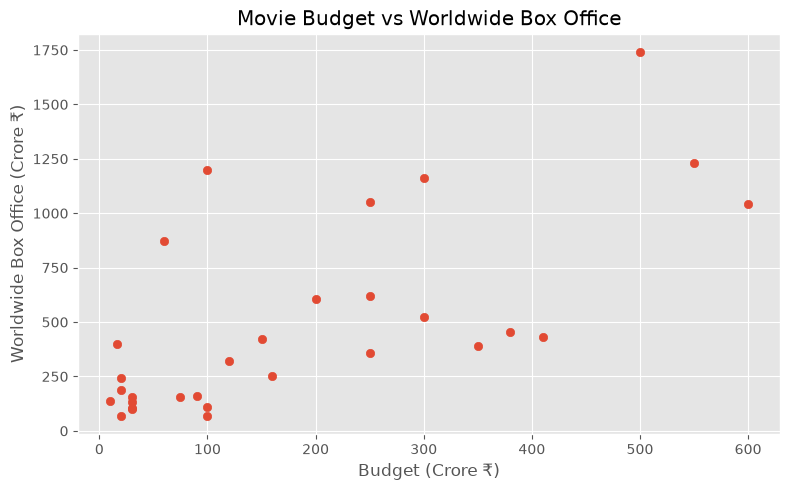

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Budget_Cr"],
    df["Worldwide_Box_Office_Cr"]
)

plt.title("Movie Budget vs Worldwide Box Office")
plt.xlabel("Budget (Crore ₹)")
plt.ylabel("Worldwide Box Office (Crore ₹)")
plt.tight_layout()
plt.show()


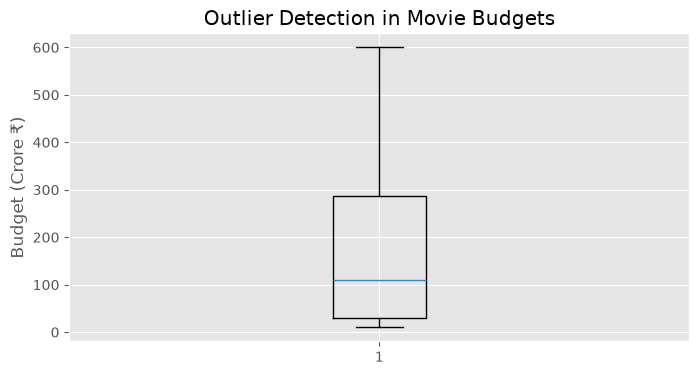

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.boxplot(df["Budget_Cr"])

plt.title("Outlier Detection in Movie Budgets")
plt.ylabel("Budget (Crore ₹)")
plt.show()


In [36]:
Q1 = df["Budget_Cr"].quantile(0.25)
Q3 = df["Budget_Cr"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


Q1: 30.0
Q3: 287.5
IQR: 257.5
Lower limit: -356.25
Upper limit: 673.75


In [37]:
outliers = df[
    (df["Budget_Cr"] < lower_limit) |
    (df["Budget_Cr"] > upper_limit)
]

outliers[["Movie_Name", "Budget_Cr"]]


,Movie_Name,Budget_Cr


In [38]:
rating_correlation = df["IMDb_Rating"].corr(
    df["Worldwide_Box_Office_Cr"]
)

print(
    "IMDb Rating vs Box Office Correlation:",
    round(rating_correlation, 2)
)


IMDb Rating vs Box Office Correlation: -0.21


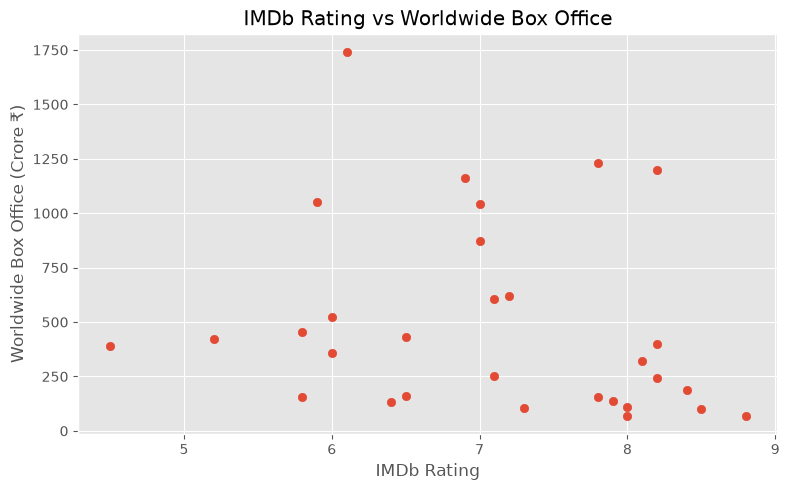

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["IMDb_Rating"],
    df["Worldwide_Box_Office_Cr"]
)

plt.title("IMDb Rating vs Worldwide Box Office")
plt.xlabel("IMDb Rating")
plt.ylabel("Worldwide Box Office (Crore ₹)")
plt.tight_layout()
plt.show()


In [40]:
df.nlargest(5, "IMDb_Rating")[
    ["Movie_Name", "IMDb_Rating", "Worldwide_Box_Office_Cr"]
]


,Movie_Name,IMDb_Rating,Worldwide_Box_Office_Cr
19,12th Fail,8.8,70
24,Sita Ramam,8.5,100
9,Maharaja,8.4,190
13,Manjummel Boys,8.2,241
26,KGF: Chapter 2,8.2,1200


In [41]:
genre_analysis = df.groupby("Genre").agg(
    Total_Movies=("Movie_Name", "count"),
    Average_IMDb_Rating=("IMDb_Rating", "mean"),
    Average_Budget_Cr=("Budget_Cr", "mean"),
    Average_Box_Office_Cr=("Worldwide_Box_Office_Cr", "mean")
)

genre_analysis = genre_analysis.round(2)

genre_analysis


,Total_Movies,Average_IMDb_Rating,Average_Budget_Cr,Average_Box_Office_Cr
Genre,,,,
Action,1,4.50,350.0,389.00
Action Comedy,2,7.45,115.0,380.50
Action Crime,1,6.50,90.0,160.00
Action Drama,5,7.08,232.0,757.20
Action Sci-Fi,1,5.80,380.0,456.00
Action Thriller,5,6.84,213.2,717.60
Biographical Action,1,8.10,120.0,320.00
Comedy Heist,1,5.80,75.0,157.00
Crime Drama,1,8.00,100.0,111.00


In [42]:
genre_analysis.sort_values(
    by="Average_IMDb_Rating",
    ascending=False
)


,Total_Movies,Average_IMDb_Rating,Average_Budget_Cr,Average_Box_Office_Cr
Genre,,,,
Drama,1,8.80,20.0,70.00
Romantic Drama,1,8.50,30.0,100.00
Crime Thriller,1,8.40,20.0,190.00
Survival Thriller,1,8.20,20.0,241.00
Biographical Action,1,8.10,120.0,320.00
Crime Drama,1,8.00,100.0,111.00
Romantic Comedy,1,7.90,10.0,136.00
Period Action,1,7.80,550.0,1230.00
Action Comedy,2,7.45,115.0,380.50


In [43]:
genre_analysis.sort_values(
    by="Average_Box_Office_Cr",
    ascending=False
)


,Total_Movies,Average_IMDb_Rating,Average_Budget_Cr,Average_Box_Office_Cr
Genre,,,,
Period Action,1,7.80,550.0,1230.00
Sci-Fi Action,1,7.00,600.0,1042.00
Action Drama,5,7.08,232.0,757.20
Action Thriller,5,6.84,213.2,717.60
Horror Comedy,3,6.20,80.0,476.33
Action Sci-Fi,1,5.80,380.0,456.00
Fantasy Adventure,1,6.50,410.0,431.00
Action,1,4.50,350.0,389.00
Action Comedy,2,7.45,115.0,380.50


In [44]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())


Missing values in each column:
Movie_ID                      0
Movie_Name                    0
Release_Year                  0
Genre                         0
Director                      0
Lead_Actor                    0
Language                      0
Budget_Cr                     0
Worldwide_Box_Office_Cr       0
IMDb_Rating                   0
Runtime_Minutes               0
Story_Rating_5                0
Acting_Rating_5               0
Music_Rating_5                0
Audience_Rating_5             0
Profit_Cr                     0
Box_Office_to_Budget_Ratio    0
Ratings_Average_5             0
dtype: int64

Total missing values: 0


In [45]:
print(df.dtypes)


Movie_ID                        int64
Movie_Name                        str
Release_Year                    int64
Genre                             str
Director                          str
Lead_Actor                        str
Language                          str
Budget_Cr                       int64
Worldwide_Box_Office_Cr         int64
IMDb_Rating                   float64
Runtime_Minutes                 int64
Story_Rating_5                float64
Acting_Rating_5               float64
Music_Rating_5                float64
Audience_Rating_5             float64
Profit_Cr                       int64
Box_Office_to_Budget_Ratio    float64
Ratings_Average_5             float64
dtype: object


In [46]:
print("Negative budgets:", (df["Budget_Cr"] < 0).sum())

print(
    "IMDb ratings outside 0-10:",
    ((df["IMDb_Rating"] < 0) | (df["IMDb_Rating"] > 10)).sum()
)

print("Non-positive runtimes:", (df["Runtime_Minutes"] <= 0).sum())

print("Negative box-office values:",
      (df["Worldwide_Box_Office_Cr"] < 0).sum())


Negative budgets: 0
IMDb ratings outside 0-10: 0
Non-positive runtimes: 0
Negative box-office values: 0


In [6]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate movie names:",
      df["Movie_Name"].duplicated().sum())


Duplicate rows: 0
Duplicate movie names: 0


In [7]:
df

,Movie_ID,Movie_Name,Release_Year,Genre,Director,Lead_Actor,Language,Budget_Cr,Worldwide_Box_Office_Cr,IMDb_Rating,Runtime_Minutes,Story_Rating_5,Acting_Rating_5,Music_Rating_5,Audience_Rating_5,Profit_Cr,Box_Office_to_Budget_Ratio,Ratings_Average_5
0,1,Kalki 2898 AD,2024,Sci-Fi Action,Nag Ashwin,Prabhas,Telugu,600,1042,7.0,180,3.5,4.2,4.0,4.3,442,1.74,4.00
1,2,Pushpa 2: The Rule,2024,Action Drama,Sukumar,Allu Arjun,Telugu,500,1742,6.1,200,4.1,4.4,4.2,4.5,1242,3.48,4.30
2,3,Devara: Part 1,2024,Action Drama,Koratala Siva,N. T. Rama Rao Jr.,Telugu,300,521,6.0,178,3.4,3.8,3.7,3.9,221,1.74,3.70
3,4,Stree 2,2024,Horror Comedy,Amar Kaushik,Rajkummar Rao,Hindi,60,874,7.0,149,4.2,4.3,4.4,4.4,814,14.57,4.32
4,5,Bhool Bhulaiyaa 3,2024,Horror Comedy,Anees Bazmee,Kartik Aaryan,Hindi,150,423,5.2,158,3.3,3.7,3.6,3.8,273,2.82,3.60
5,6,Singham Again,2024,Action,Rohit Shetty,Ajay Devgn,Hindi,350,389,4.5,144,3.2,3.5,3.4,3.7,39,1.11,3.45
6,7,Fighter,2024,Action Thriller,Siddharth Anand,Hrithik Roshan,Hindi,250,358,6.0,166,3.7,4.0,3.8,4.1,108,1.43,3.90
7,8,The Greatest of All Time (GOAT),2024,Action Sci-Fi,Venkat Prabhu,Vijay,Tamil,380,456,5.8,183,3.8,4.1,4.0,4.2,76,1.20,4.02
8,9,Amaran,2024,Biographical Action,Rajkumar Periasamy,Sivakarthikeyan,Tamil,120,320,8.1,169,4.5,4.6,4.6,4.5,200,2.67,4.55
9,10,Maharaja,2024,Crime Thriller,Nithilan Saminathan,Vijay Sethupathi,Tamil,20,190,8.4,141,4.4,4.5,4.5,4.4,170,9.50,4.45


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
df.head()

,Movie_ID,Movie_Name,Release_Year,Genre,Director,Lead_Actor,Language,Budget_Cr,Worldwide_Box_Office_Cr,IMDb_Rating,Runtime_Minutes,Story_Rating_5,Acting_Rating_5,Music_Rating_5,Audience_Rating_5,Profit_Cr,Box_Office_to_Budget_Ratio,Ratings_Average_5
0,1,Kalki 2898 AD,2024,Sci-Fi Action,Nag Ashwin,Prabhas,Telugu,600,1042,7.0,180,3.5,4.2,4.0,4.3,442,1.74,4.00
1,2,Pushpa 2: The Rule,2024,Action Drama,Sukumar,Allu Arjun,Telugu,500,1742,6.1,200,4.1,4.4,4.2,4.5,1242,3.48,4.30
2,3,Devara: Part 1,2024,Action Drama,Koratala Siva,N. T. Rama Rao Jr.,Telugu,300,521,6.0,178,3.4,3.8,3.7,3.9,221,1.74,3.70
3,4,Stree 2,2024,Horror Comedy,Amar Kaushik,Rajkummar Rao,Hindi,60,874,7.0,149,4.2,4.3,4.4,4.4,814,14.57,4.32
4,5,Bhool Bhulaiyaa 3,2024,Horror Comedy,Anees Bazmee,Kartik Aaryan,Hindi,150,423,5.2,158,3.3,3.7,3.6,3.8,273,2.82,3.60


In [10]:
top_5_movies = df.nlargest(
    5, "Worldwide_Box_Office_Cr"
)

top_5_movies[["Movie_Name", "Worldwide_Box_Office_Cr"]]

,Movie_Name,Worldwide_Box_Office_Cr
1,Pushpa 2: The Rule,1742
25,RRR,1230
26,KGF: Chapter 2,1200
20,Jawan,1160
28,Pathaan,1050


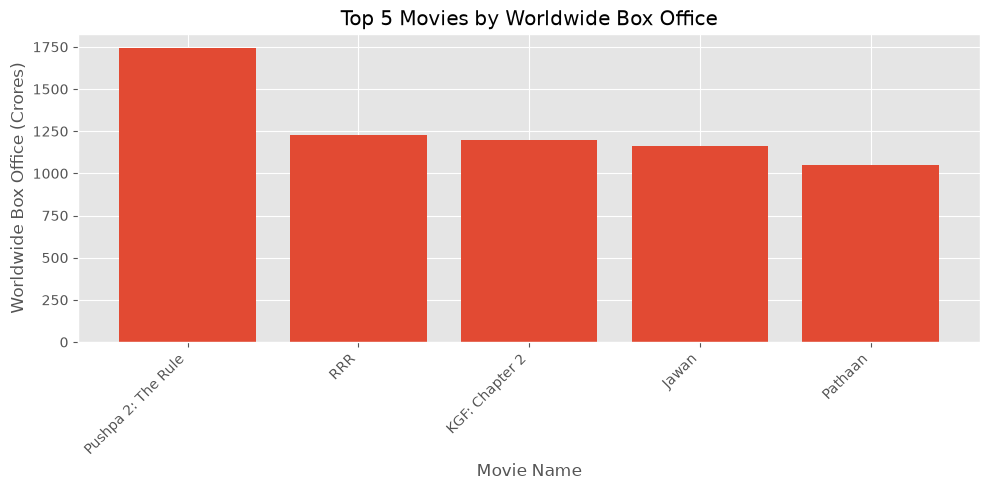

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_5_movies["Movie_Name"],
    top_5_movies["Worldwide_Box_Office_Cr"]
)

plt.title("Top 5 Movies by Worldwide Box Office")
plt.xlabel("Movie Name")
plt.ylabel("Worldwide Box Office (Crores)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [12]:
df["IMDb_Rating"].describe()

count    30.000000
mean      7.073333
std       1.087843
min       4.500000
25%       6.175000
50%       7.100000
75%       8.000000
max       8.800000
Name: IMDb_Rating, dtype: float64

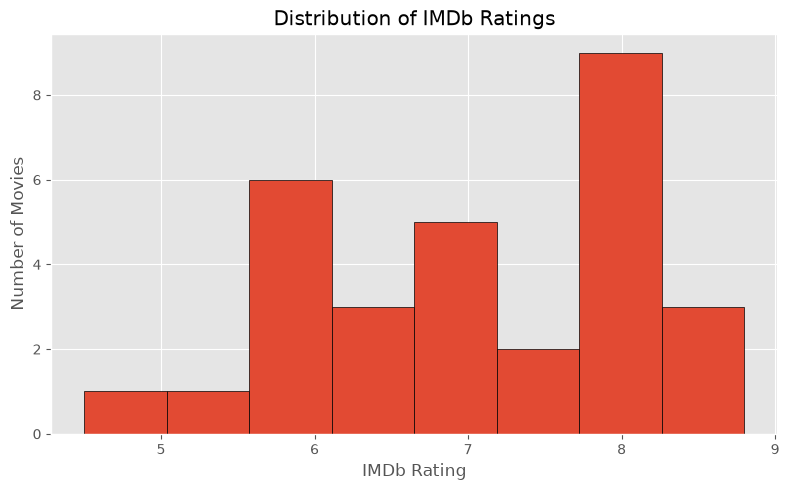

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["IMDb_Rating"],
    bins=8,
    edgecolor="black"
)

plt.title("Distribution of IMDb Ratings")
plt.xlabel("IMDb Rating")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

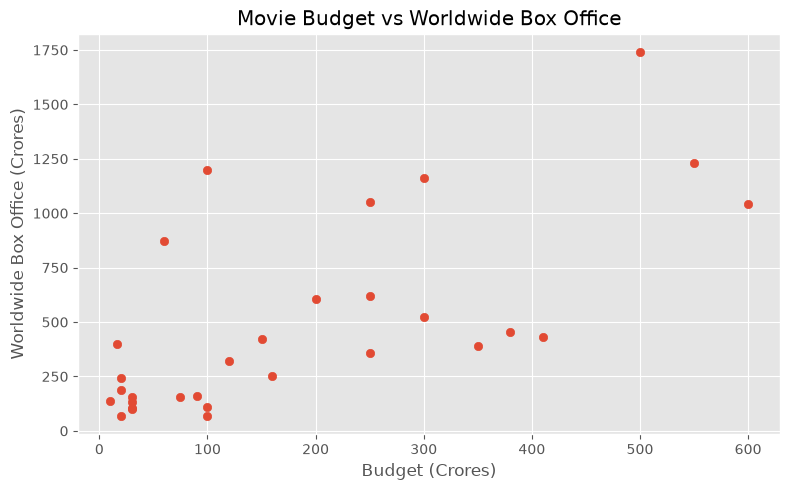

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Budget_Cr"],
    df["Worldwide_Box_Office_Cr"]
)

plt.title("Movie Budget vs Worldwide Box Office")
plt.xlabel("Budget (Crores)")
plt.ylabel("Worldwide Box Office (Crores)")

plt.tight_layout()
plt.show()

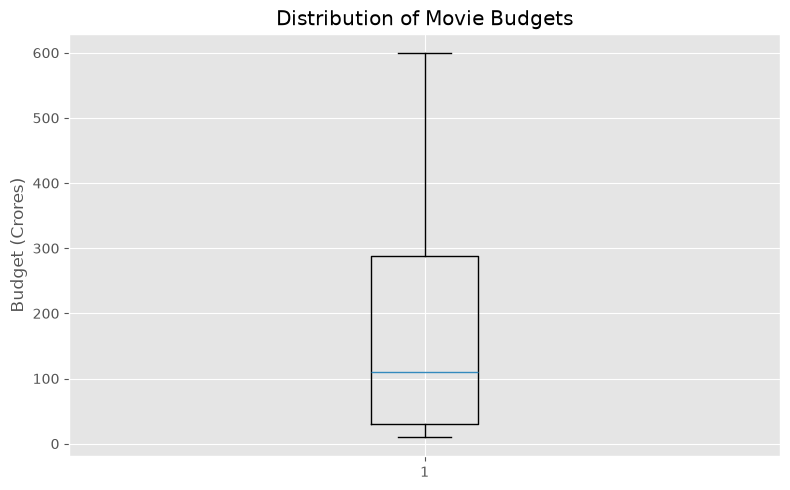

In [15]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["Budget_Cr"])

plt.title("Distribution of Movie Budgets")
plt.ylabel("Budget (Crores)")

plt.tight_layout()
plt.show()

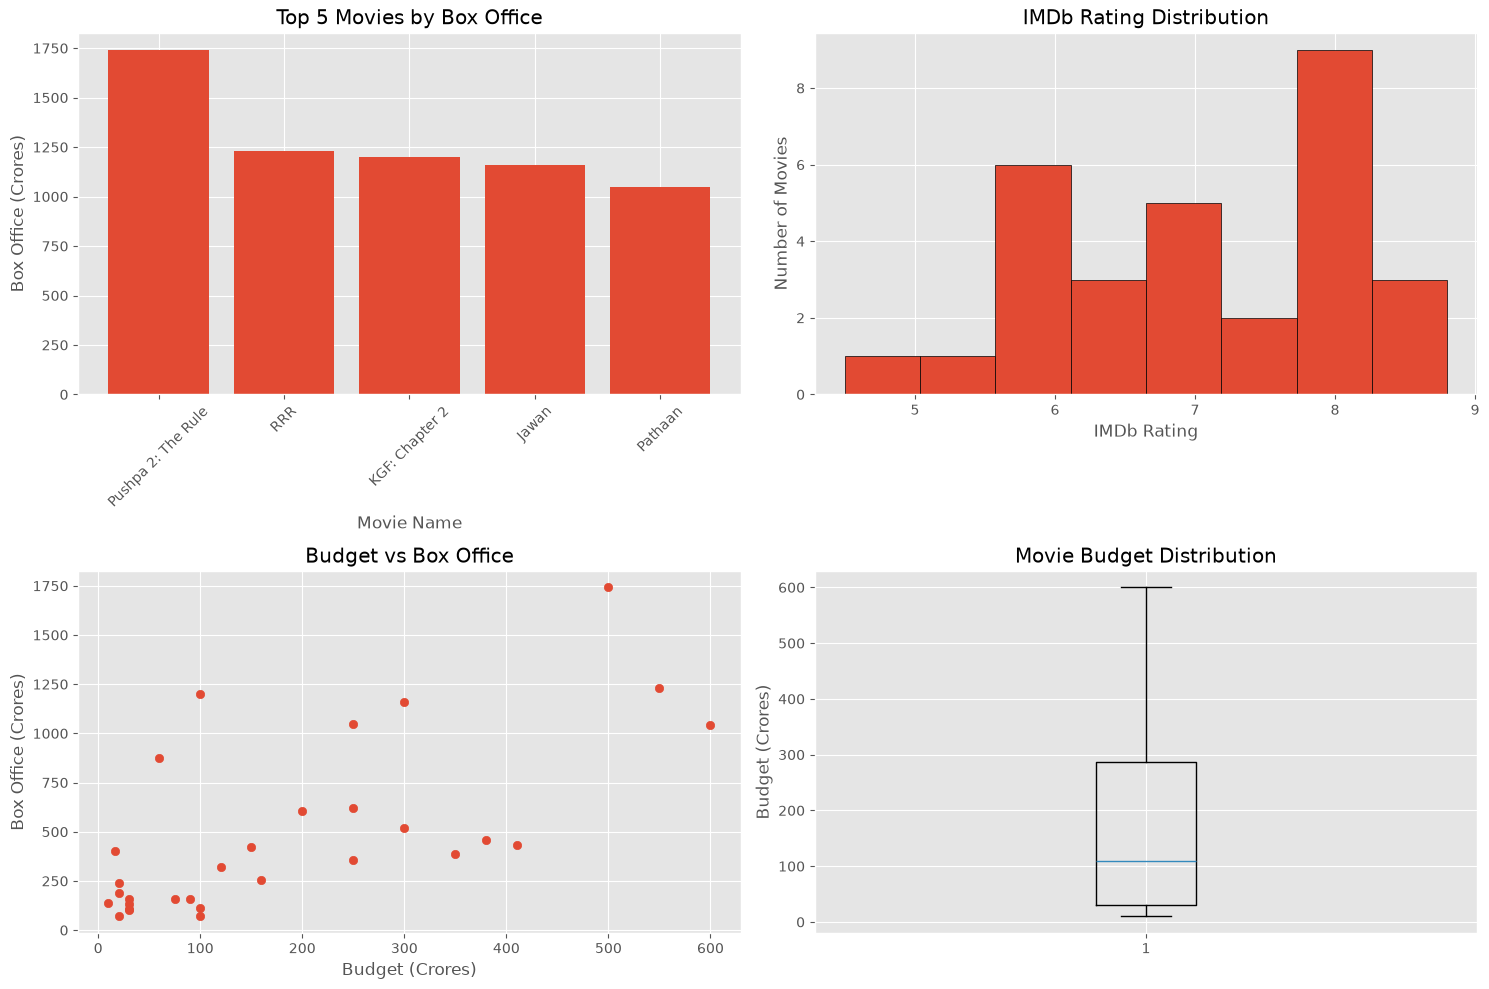

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Chart 1: Top 5 Movies by Box Office
top_5_movies = df.nlargest(
    5, "Worldwide_Box_Office_Cr"
)

axes[0, 0].bar(
    top_5_movies["Movie_Name"],
    top_5_movies["Worldwide_Box_Office_Cr"]
)
axes[0, 0].set_title("Top 5 Movies by Box Office")
axes[0, 0].set_xlabel("Movie Name")
axes[0, 0].set_ylabel("Box Office (Crores)")
axes[0, 0].tick_params(axis="x", rotation=45)

# Chart 2: IMDb Rating Distribution
axes[0, 1].hist(df["IMDb_Rating"], bins=8, edgecolor="black")
axes[0, 1].set_title("IMDb Rating Distribution")
axes[0, 1].set_xlabel("IMDb Rating")
axes[0, 1].set_ylabel("Number of Movies")

# Chart 3: Budget vs Box Office
axes[1, 0].scatter(
    df["Budget_Cr"],
    df["Worldwide_Box_Office_Cr"]
)
axes[1, 0].set_title("Budget vs Box Office")
axes[1, 0].set_xlabel("Budget (Crores)")
axes[1, 0].set_ylabel("Box Office (Crores)")

# Chart 4: Budget Distribution
axes[1, 1].boxplot(df["Budget_Cr"])
axes[1, 1].set_title("Movie Budget Distribution")
axes[1, 1].set_ylabel("Budget (Crores)")

# Adjust spacing and display
plt.tight_layout()
plt.show()

In [17]:
plt.tight_layout()

plt.savefig(
    "Movie_Analysis_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1200x800 with 0 Axes>

In [18]:
import os
print(os.getcwd())

C:\Users\acer


In [19]:
top_movie = df.loc[
    df["Worldwide_Box_Office_Cr"].idxmax()
]

print("Highest-grossing movie:", top_movie["Movie_Name"])
print(
    "Worldwide box office:",
    top_movie["Worldwide_Box_Office_Cr"],
    "crores"
)

Highest-grossing movie: Pushpa 2: The Rule
Worldwide box office: 1742 crores


In [20]:
average_box_office = df["Worldwide_Box_Office_Cr"].mean()

difference = (
    top_movie["Worldwide_Box_Office_Cr"]
    - average_box_office
)

print("Average box office:", round(average_box_office, 2), "crores")
print("Highest movie's revenue above average:", round(difference, 2), "crores")

Average box office: 490.13 crores
Highest movie's revenue above average: 1251.87 crores


In [21]:
top_rated_movie = df.loc[df["IMDb_Rating"].idxmax()]

print("Highest-rated movie:", top_rated_movie["Movie_Name"])
print("IMDb Rating:", top_rated_movie["IMDb_Rating"])
print(
    "Worldwide Box Office:",
    top_rated_movie["Worldwide_Box_Office_Cr"],
    "crores"
)

Highest-rated movie: 12th Fail
IMDb Rating: 8.8
Worldwide Box Office: 70 crores


In [22]:
print("Highest-grossing movie:")
print(top_movie["Movie_Name"])

print("\nHighest-rated movie:")
print(top_rated_movie["Movie_Name"])

if top_movie["Movie_Name"] == top_rated_movie["Movie_Name"]:
    print("\nBoth are the same movie!")
else:
    print("\nThey are different movies!")

Highest-grossing movie:
Pushpa 2: The Rule

Highest-rated movie:
12th Fail

They are different movies!


In [23]:
top_rated_movies = df.nlargest(5, "IMDb_Rating")

top_rated_movies[
    ["Movie_Name", "IMDb_Rating", "Worldwide_Box_Office_Cr"]
]

,Movie_Name,IMDb_Rating,Worldwide_Box_Office_Cr
19,12th Fail,8.8,70
24,Sita Ramam,8.5,100
9,Maharaja,8.4,190
13,Manjummel Boys,8.2,241
26,KGF: Chapter 2,8.2,1200


In [24]:
correlation = df[
    ["IMDb_Rating", "Worldwide_Box_Office_Cr"]
].corr()

print(correlation)

                         IMDb_Rating  Worldwide_Box_Office_Cr
IMDb_Rating                 1.000000                -0.209332
Worldwide_Box_Office_Cr    -0.209332                 1.000000


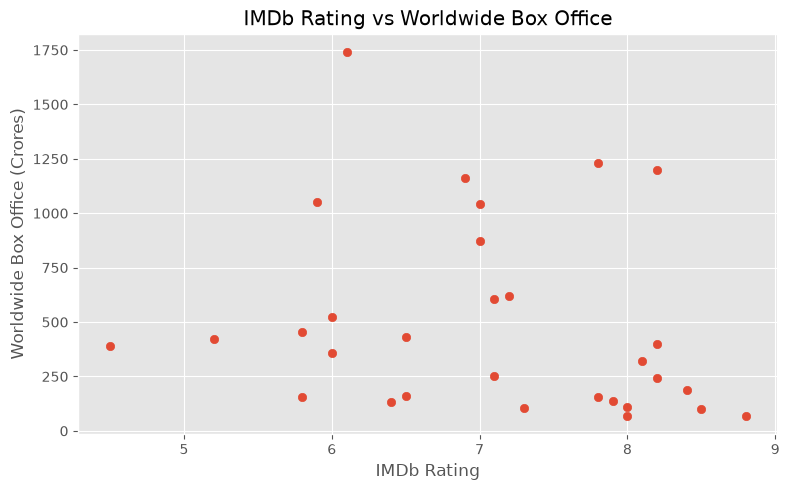

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["IMDb_Rating"],
    df["Worldwide_Box_Office_Cr"]
)

plt.title("IMDb Rating vs Worldwide Box Office")
plt.xlabel("IMDb Rating")
plt.ylabel("Worldwide Box Office (Crores)")

plt.tight_layout()
plt.show()

In [26]:
print("MOVIE ANALYSIS - EDA FINDINGS REPORT")
print("=" * 45)

# Finding 1
print("\n1. BOX OFFICE PERFORMANCE")
print("Identified the highest-grossing movie in the dataset.")

# Finding 2
print("\n2. IMDb RATINGS")
print("The highest-rated movie differs from the highest-grossing movie.")

# Finding 3
print("\n3. CORRELATION ANALYSIS")
print(f"IMDb Rating vs Box Office correlation: {correlation.loc['IMDb_Rating', 'Worldwide_Box_Office_Cr']:.2f}")
print("The relationship is weak and negative in this dataset.")

# Finding 4
print("\n4. BUSINESS INTERPRETATION")
print("IMDb rating alone does not explain box-office performance.")

print("\n" + "=" * 45)
print("EDA Lesson 9 report completed!")

MOVIE ANALYSIS - EDA FINDINGS REPORT

1. BOX OFFICE PERFORMANCE
Identified the highest-grossing movie in the dataset.

2. IMDb RATINGS
The highest-rated movie differs from the highest-grossing movie.

3. CORRELATION ANALYSIS
IMDb Rating vs Box Office correlation: -0.21
The relationship is weak and negative in this dataset.

4. BUSINESS INTERPRETATION
IMDb rating alone does not explain box-office performance.

EDA Lesson 9 report completed!


In [28]:
print("MOVIE ANALYSIS - FINAL PROJECT")
print("=" * 40)

print("Dataset shape:", df.shape)
print("Total movies:", len(df))
print("Total columns:", len(df.columns))

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

MOVIE ANALYSIS - FINAL PROJECT
Dataset shape: (30, 18)
Total movies: 30
Total columns: 18

Missing values: 0
Duplicate rows: 0

Column names:
['Movie_ID', 'Movie_Name', 'Release_Year', 'Genre', 'Director', 'Lead_Actor', 'Language', 'Budget_Cr', 'Worldwide_Box_Office_Cr', 'IMDb_Rating', 'Runtime_Minutes', 'Story_Rating_5', 'Acting_Rating_5', 'Music_Rating_5', 'Audience_Rating_5', 'Profit_Cr', 'Box_Office_to_Budget_Ratio', 'Ratings_Average_5']


In [29]:
print("FINAL MOVIE ANALYSIS SUMMARY")
print("=" * 40)

print("\n1. Average IMDb Rating:")
print(round(df["IMDb_Rating"].mean(), 2))

print("\n2. Highest-Grossing Movie:")
top_movie = df.loc[
    df["Worldwide_Box_Office_Cr"].idxmax()
]
print(top_movie["Movie_Name"])
print(
    "Box Office:",
    top_movie["Worldwide_Box_Office_Cr"],
    "crores"
)

print("\n3. Highest-Rated Movie:")
top_rated_movie = df.loc[
    df["IMDb_Rating"].idxmax()
]
print(top_rated_movie["Movie_Name"])
print("IMDb Rating:", top_rated_movie["IMDb_Rating"])

print("\n4. Average Box Office:")
print(
    round(df["Worldwide_Box_Office_Cr"].mean(), 2),
    "crores"
)

print("\n5. Rating vs Box Office Correlation:")
print(
    round(
        df["IMDb_Rating"].corr(
            df["Worldwide_Box_Office_Cr"]
        ),
        2
    )
)

FINAL MOVIE ANALYSIS SUMMARY

1. Average IMDb Rating:
7.07

2. Highest-Grossing Movie:
Pushpa 2: The Rule
Box Office: 1742 crores

3. Highest-Rated Movie:
12th Fail
IMDb Rating: 8.8

4. Average Box Office:
490.13 crores

5. Rating vs Box Office Correlation:
-0.21


In [30]:
df.to_excel("Movie_Analysis_Final.xlsx", index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [31]:
# Calculate project results
total_movies = len(df)
total_columns = len(df.columns)
missing_values = int(df.isnull().sum().sum())
duplicate_rows = int(df.duplicated().sum())

top_movie = df.loc[df["Worldwide_Box_Office_Cr"].idxmax()]
top_rated_movie = df.loc[df["IMDb_Rating"].idxmax()]

average_rating = df["IMDb_Rating"].mean()
average_box_office = df["Worldwide_Box_Office_Cr"].mean()

correlation = df["IMDb_Rating"].corr(
    df["Worldwide_Box_Office_Cr"]
)

# Create the final report
report = f"""
# Movie Analysis — Exploratory Data Analysis Report

## 1. Project Overview
This project explores a movie dataset using Python, Pandas,
and Matplotlib. The objective is to understand movie ratings,
box-office performance, budgets, and data patterns.

## 2. Dataset Overview
- Total movie records: {total_movies}
- Total columns: {total_columns}
- Missing values: {missing_values}
- Duplicate rows: {duplicate_rows}

## 3. Key Findings
- Highest-grossing movie: {top_movie['Movie_Name']}
- Its worldwide box office: {top_movie['Worldwide_Box_Office_Cr']} crores
- Highest-rated movie: {top_rated_movie['Movie_Name']}
- Its IMDb rating: {top_rated_movie['IMDb_Rating']}
- Average IMDb rating: {average_rating:.2f}
- Average worldwide box office: {average_box_office:.2f} crores
- IMDb rating vs box-office correlation: {correlation:.2f}

## 4. Methods Used
- Data inspection and descriptive statistics
- Missing-value and duplicate checks
- Exploratory data analysis
- Grouping and summary calculations
- Correlation analysis
- Visualization using bar charts, histograms,
  scatter plots, and box plots

## 5. Conclusion
The analysis summarizes movie ratings, budgets, and
box-office performance in the dataset. IMDb ratings
and box-office revenue measure different aspects of
movie performance. Correlation alone does not establish
causation.

## 6. Limitations
The dataset contains illustrative practice values.
Results should not be treated as verified real-world
movie statistics or used to make industry-wide claims.

## 7. Tools Used
Python, Pandas, Matplotlib, Jupyter Notebook
"""

with open("Movie_Analysis_Final_Report.md", "w", encoding="utf-8") as file:
    file.write(report)

print("Final report created successfully!")

Final report created successfully!


In [32]:
import os

files_to_check = [
    "Movie_Analysis_Final.xlsx",
    "Movie_Analysis_Dashboard.png",
    "Movie_Analysis_Final_Report.md"
]

for filename in files_to_check:
    print(filename, "—", "Found" if os.path.exists(filename) else "Not found")

Movie_Analysis_Final.xlsx — Found
Movie_Analysis_Dashboard.png — Found
Movie_Analysis_Final_Report.md — Found


File exists: True
File size: 40902 bytes


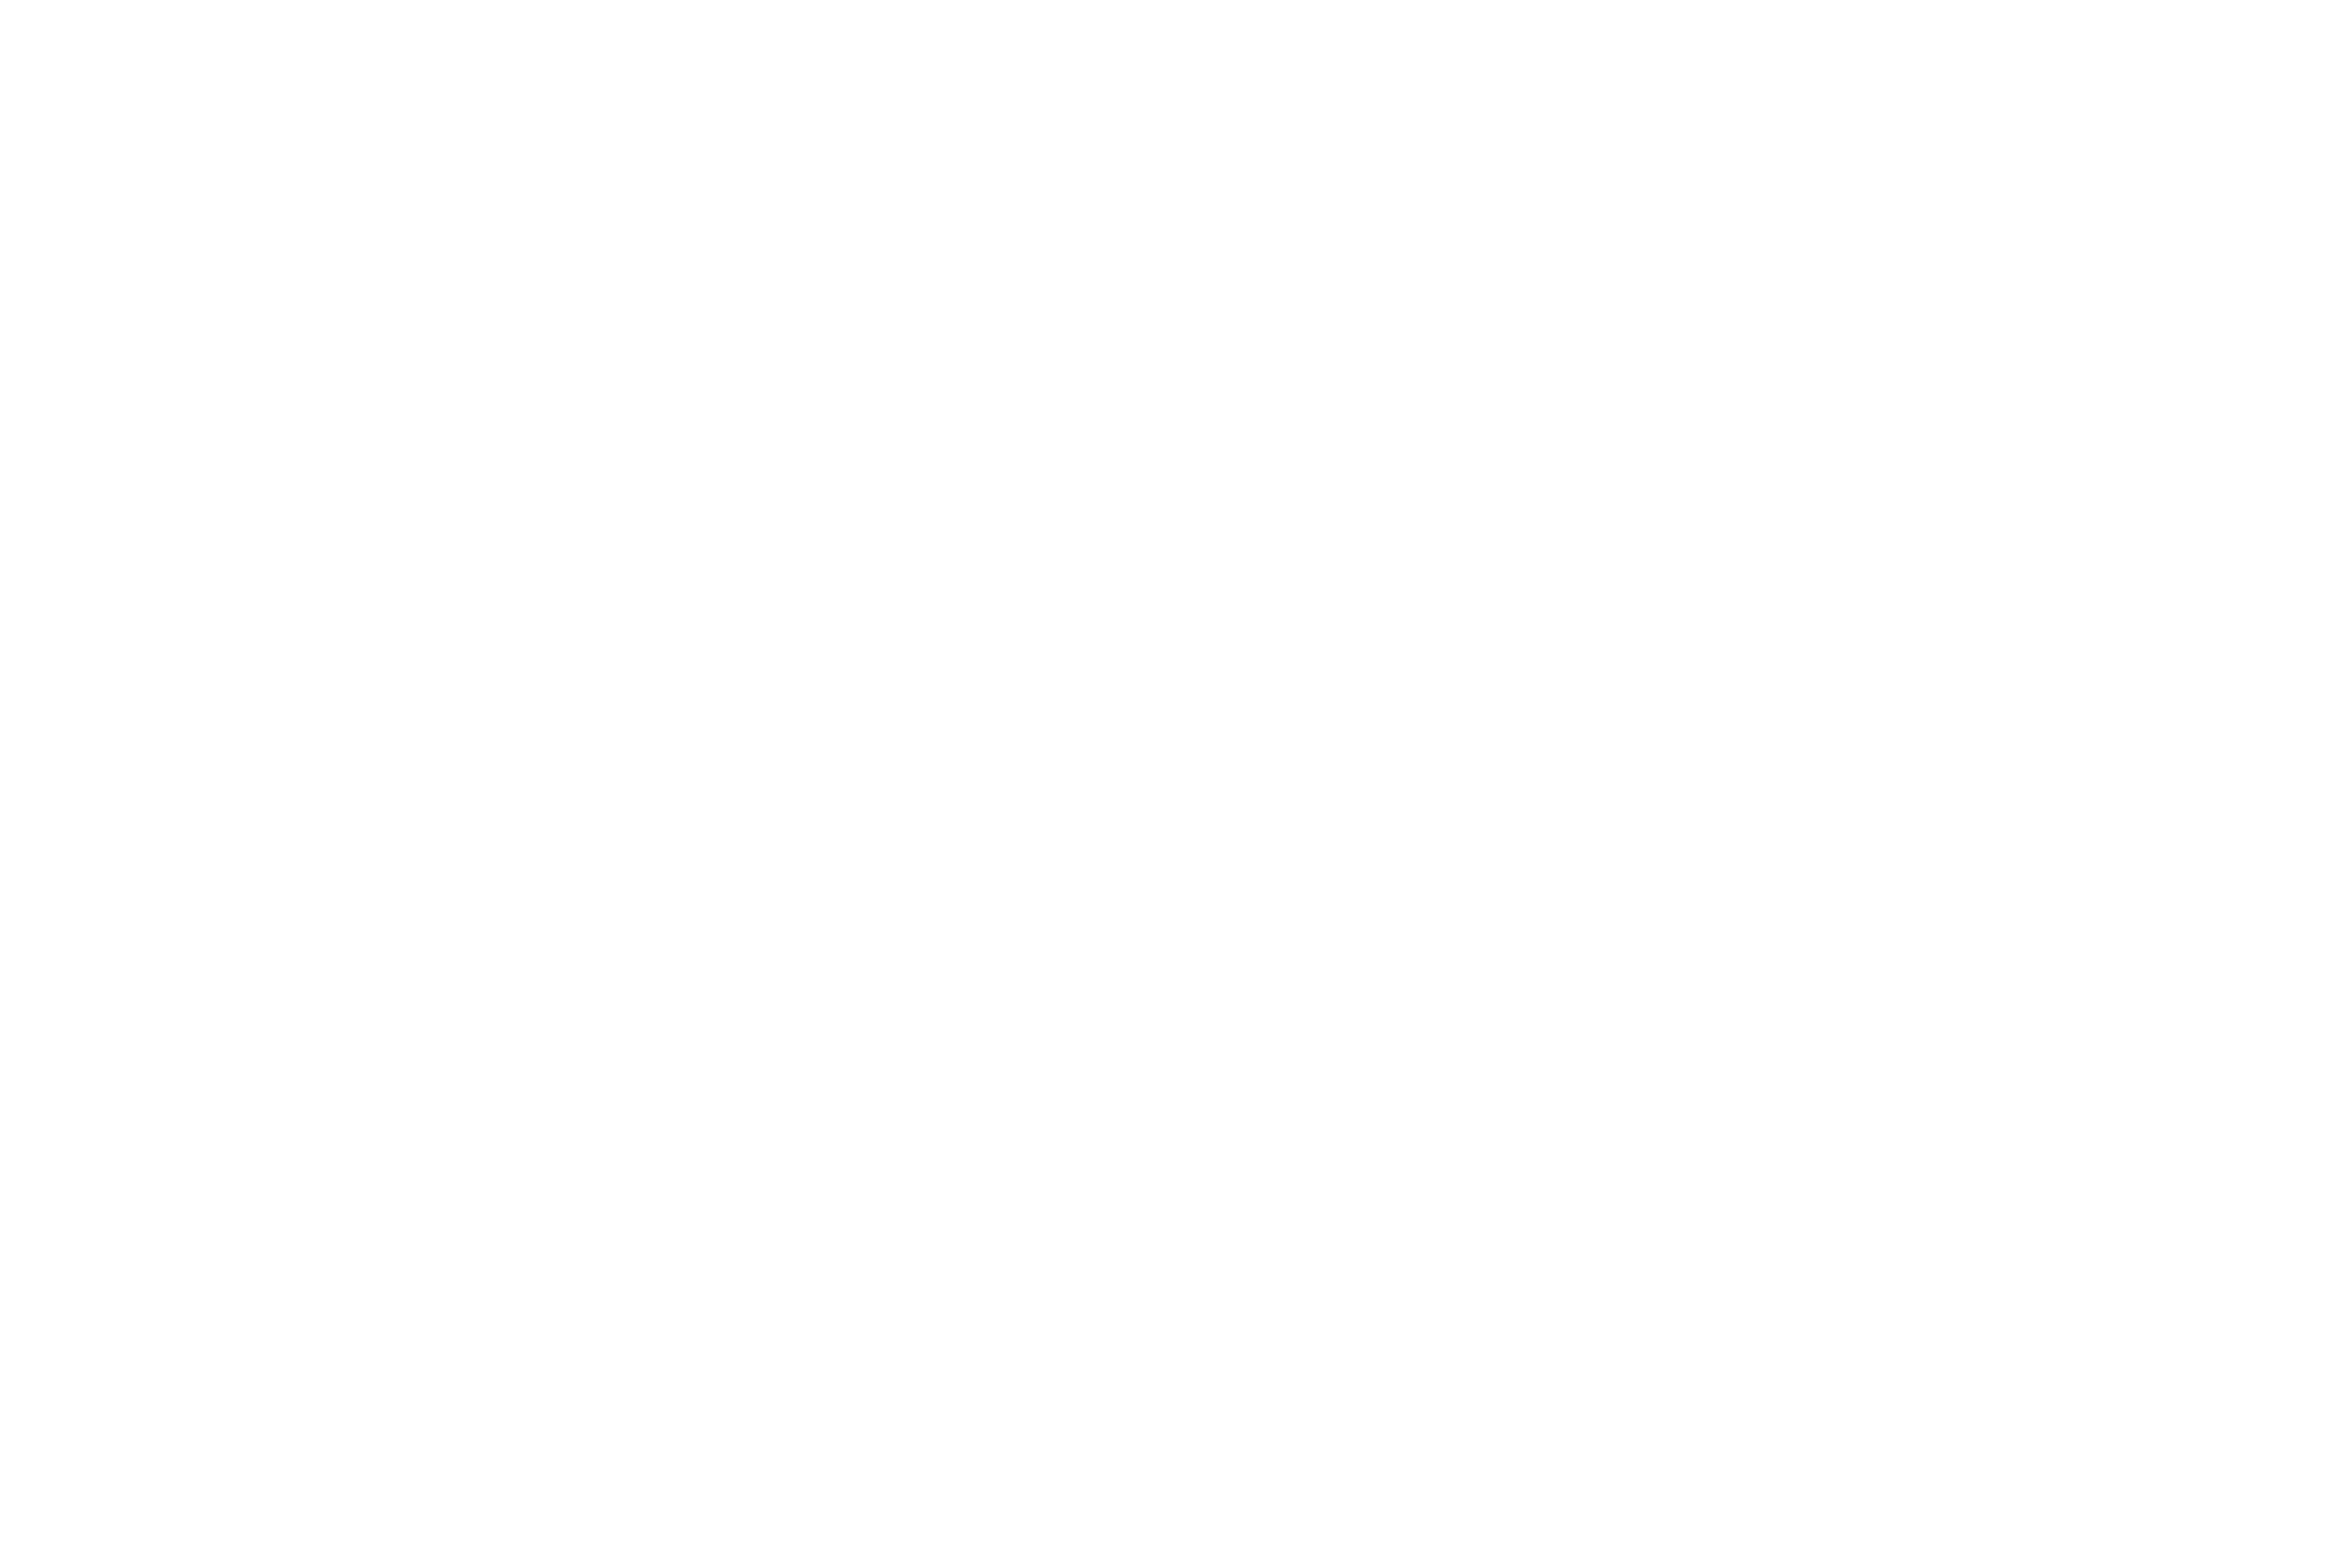

In [34]:
import os
from IPython.display import display, Image

filename = "Movie_Analysis_Dashboard.png"

print("File exists:", os.path.exists(filename))

if os.path.exists(filename):
    print("File size:", os.path.getsize(filename), "bytes")
    display(Image(filename=filename))
else:
    print("Dashboard not found in the current folder.")

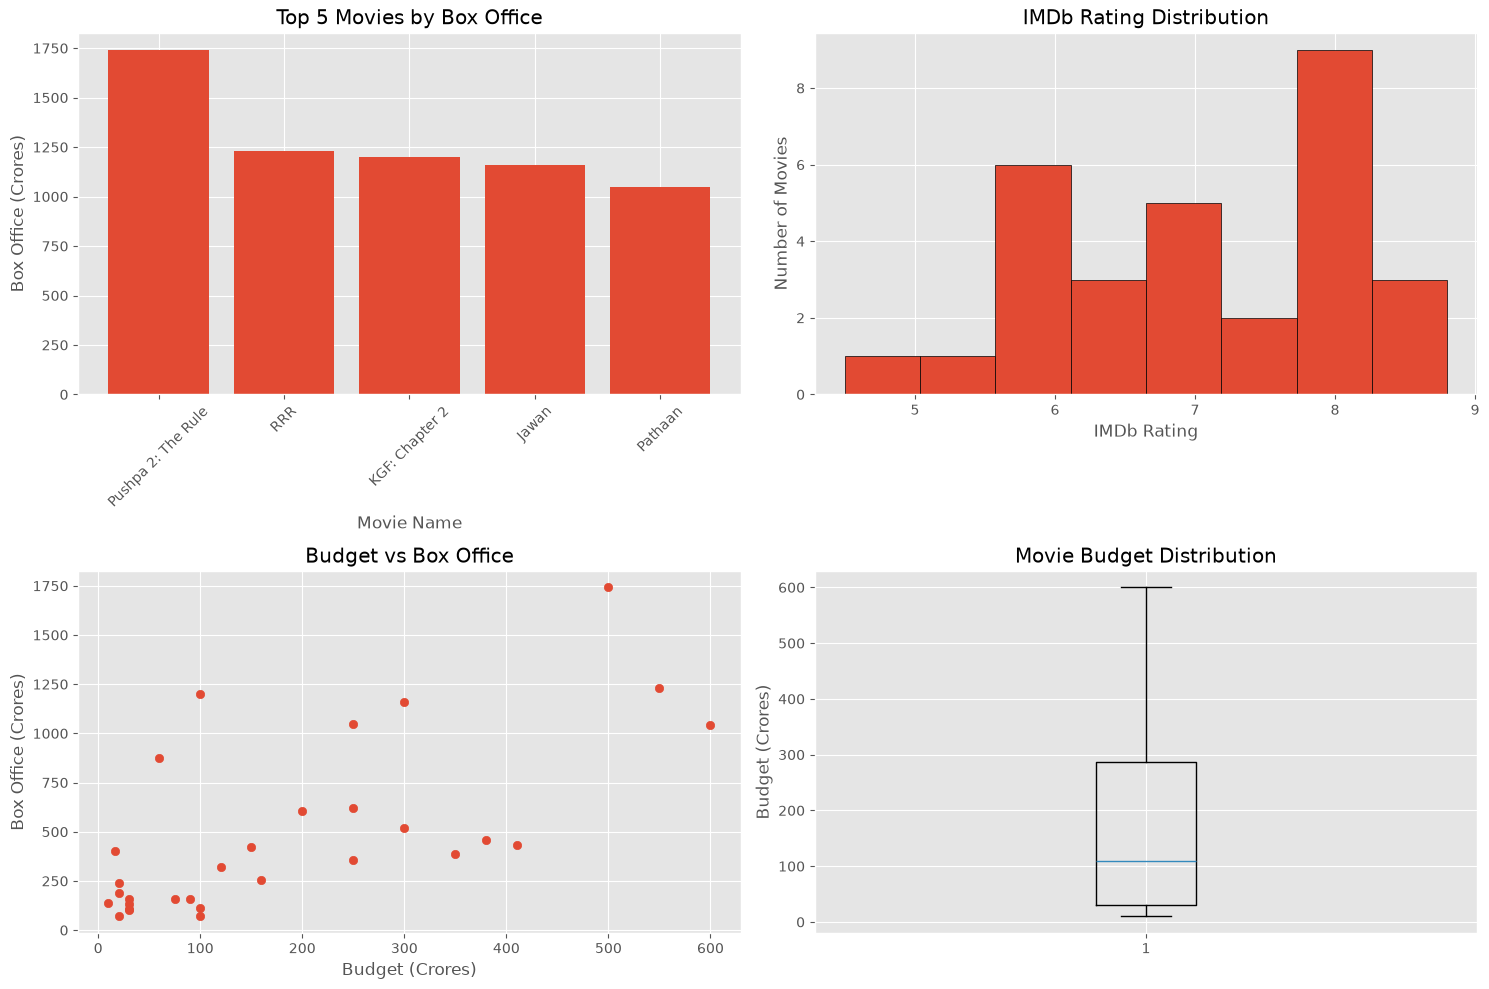

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Chart 1: Top 5 Movies by Box Office
top_5_movies = df.nlargest(
    5, "Worldwide_Box_Office_Cr"
)

axes[0, 0].bar(
    top_5_movies["Movie_Name"],
    top_5_movies["Worldwide_Box_Office_Cr"]
)
axes[0, 0].set_title("Top 5 Movies by Box Office")
axes[0, 0].set_xlabel("Movie Name")
axes[0, 0].set_ylabel("Box Office (Crores)")
axes[0, 0].tick_params(axis="x", rotation=45)

# Chart 2: IMDb Rating Distribution
axes[0, 1].hist(df["IMDb_Rating"], bins=8, edgecolor="black")
axes[0, 1].set_title("IMDb Rating Distribution")
axes[0, 1].set_xlabel("IMDb Rating")
axes[0, 1].set_ylabel("Number of Movies")

# Chart 3: Budget vs Box Office
axes[1, 0].scatter(
    df["Budget_Cr"],
    df["Worldwide_Box_Office_Cr"]
)
axes[1, 0].set_title("Budget vs Box Office")
axes[1, 0].set_xlabel("Budget (Crores)")
axes[1, 0].set_ylabel("Box Office (Crores)")

# Chart 4: Budget Distribution
axes[1, 1].boxplot(df["Budget_Cr"])
axes[1, 1].set_title("Movie Budget Distribution")
axes[1, 1].set_ylabel("Budget (Crores)")

# Adjust spacing and display
plt.tight_layout()
plt.show()

In [36]:
plt.tight_layout()

plt.savefig(
    "Movie_Analysis_Dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1200x800 with 0 Axes>

In [37]:
from PIL import Image
import os

filename = "Movie_Analysis_Dashboard.png"

print("File size:", os.path.getsize(filename), "bytes")

try:
    img = Image.open(filename)
    print("Image format:", img.format)
    print("Image dimensions:", img.size)
    img.verify()
    print("Image file is valid!")
except Exception as e:
    print("Image problem:", e)

File size: 40902 bytes
Image format: PNG
Image dimensions: (3660, 2460)
Image file is valid!
